# Tutorial: Parameter Fitting with the Analytical Module in Soft Potato

Extracting physical, transport, and kinetic parameters from experimental electrochemical data is one of the most common and critical tasks in electrochemistry. In traditional workflows, researchers often have to write out analytical equations by hand, determine reasonable starting guesses, perform non-linear regression, and manually write boilerplate calculations for confidence intervals and goodness-of-fit metrics.

In **Soft Potato**, the parameter fitting submodule (`softpotato.analytical.fitting`) makes extracting parameters from experimental data **as straightforward and reliable as possible**.

This is made possible because Soft Potato's `analytical` module already includes the exact, closed-form equations for electrochemistry across all its domain submodules (`step`, `voltammetry`, `secm`, `hydrodynamics`, `kinetics`, and `microelectrodes`).

---

## 1. What is `softpotato.analytical.fitting`?

> **Key Design Concept:**
>
> The fitting submodule wraps `scipy.optimize.curve_fit` and linear least-squares regression algorithms while seamlessly integrating electrochemistry domain knowledge:
>
> 1. **Closed-Form Electrochemistry Equations**: Automatically connects experimental observables ($I(t)$, $I_p$, $I_L$, $I_T$) directly to physical constants ($D$, $k^0$, $\alpha$, $A$, $RG$).
> 2. **Physically Realistic Parameter Boundaries**: Enforces valid parameter domains ($D > 0$, $0 < \alpha < 1$, $k^0 \ge 0$, $c^* > 0$, $A > 0$, $RG \ge 1.0$) to avoid unphysical local minima.
> 3. **Comprehensive Statistical Information**: Returns structured result objects (`FitResult` and specialized subclasses) containing asymptotic standard errors, parameter covariance and correlation matrices, Student's $t$ confidence intervals, and goodness-of-fit metrics ($R^2$, adjusted $R^2$, RMSE, and reduced $\chi_\nu^2$).
> 4. **General Arbitrary Curve Fitting**: Supplies `fit_curve()` to fit any user-defined mathematical function with identical diagnostic reporting and physical bounds.

### Submodule Capabilities

| Function | Electrochemical Technique | Extracted Parameters | Result Type |
| :--- | :--- | :--- | :--- |
| `fit_cottrell()` | Chronoamperometry (Planar) | Diffusion coefficient $D$, background current $I_{\text{bg}}$ | `CottrellFitResult` |
| `fit_randles_sevcik()` | Cyclic Voltammetry Peak Current | Diffusion coefficient $D$, regression slope & intercept | `RandlesSevcikFitResult` |
| `fit_secm_approach()` | SECM Approach Curves | Insulator radius ratio $RG$, vertical offset $d_{\text{offset}}$, substrate rate $\kappa$ | `SECMApproachFitResult` |
| `fit_curve()` | Arbitrary User-Coded Function | Custom parameters, full covariance & diagnostics | `FitResult` |
| `fit_levich()` | Rotating Disk Electrode (RDE) | Diffusion coefficient $D$, Levich constant $B$ | `LevichFitResult` |
| `fit_koutecky_levich()` | RDE Mixed Mass-Transport & Kinetics | Rate constant $k^0$, kinetic current $I_K$, diffusion coefficient $D$ | `KouteckyLevichFitResult` |
| `fit_tafel()` | High-Field Tafel Kinetics | Exchange current $I_0$, transfer coefficient $\alpha$ | `TafelFitResult` |
| `fit_butler_volmer()` | Full-Range Butler–Volmer | Exchange current $I_0$, transfer coefficient $\alpha$, equilibrium potential $E_{\text{eq}}$ | `ButlerVolmerFitResult` |
| `fit_microdisc_transient()` | Ultramicroelectrode Transients | Diffusion coefficient $D$ or disc radius $a$ | `MicrodiscFitResult` |

The following sections walk through step-by-step examples of generating noisy "experimental" data using Soft Potato analytical equations and extracting parameters with `fit_cottrell()`, `fit_randles_sevcik()`, `fit_secm_approach()`, and `fit_curve()`.


---

## 2. Chronoamperometry: `fit_cottrell()`

The Cottrell equation calculates the diffusion-controlled Faradaic current transient $I(t)$ following an instantaneous potential step into the mass-transport-limited regime:

$$I(t) = \frac{n F A \sqrt{D} c^*}{\sqrt{\pi t}} + I_{\text{bg}}$$

where:
- $n$ is the number of electrons transferred per molecule,
- $F$ is Faraday's constant ($96485.3321\text{ C}\cdot\text{mol}^{-1}$),
- $A$ is the electrode area ($\text{cm}^2$ or $\text{m}^2$),
- $c^*$ is the bulk reactant concentration ($\text{mol/cm}^3$ or $\text{mol/m}^3$),
- $D$ is the diffusion coefficient ($\text{cm}^2/\text{s}$ or $\text{m}^2/\text{s}$),
- $I_{\text{bg}}$ is a background baseline or charging current offset.

The function `fit_cottrell()` accepts measured currents and time points and fits either:
- Linearly (`method="linear"`): linear least-squares regression of $I$ vs. $t^{-1/2}$.
- Non-linearly (`method="nonlinear"`): bounded non-linear curve fitting of $I(t)$ vs. $t$.

Below, we generate synthetic "experimental data" using `softpotato.analytical.step.cottrell`, inject random noise, and extract $D$.


=== Cottrell Chronoamperometry Fitting Results ===
True D:              1.5000e-05 cm²/s
Extracted D:         1.4867e-05 ± 1.4839e-07 cm²/s
95% Confidence Int:  [1.4570e-05, 1.5167e-05] cm²/s
Extracted I_bg:      1.1327e-04 A
Coefficient R²:      0.998806
Adjusted R²:         0.998781
RMSE:                3.5648e-04 A


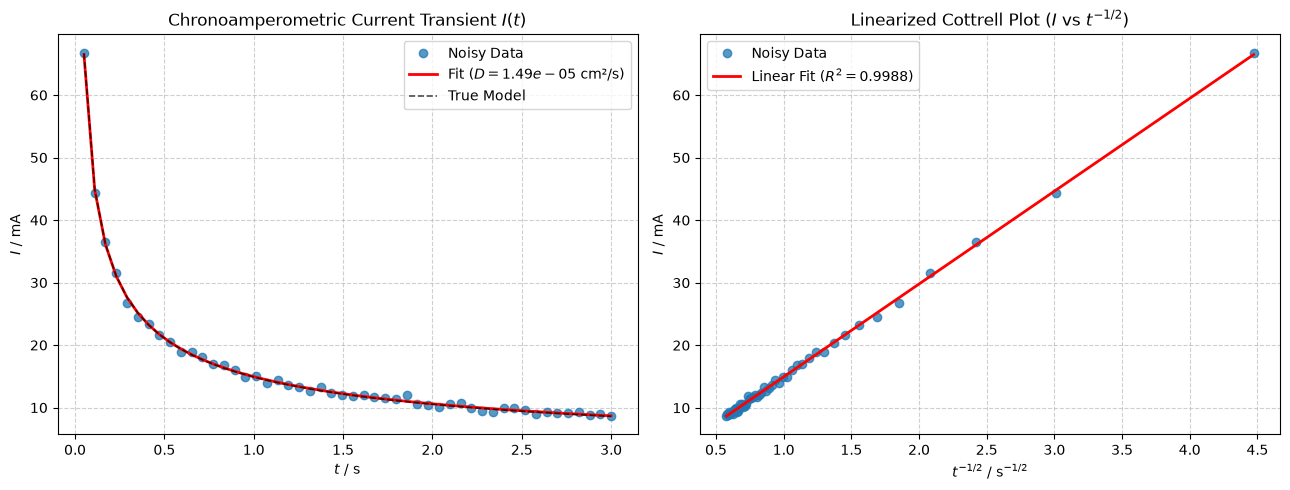

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from softpotato.analytical.step import cottrell
from softpotato.analytical.fitting import fit_cottrell

# Seed for reproducible synthetic experimental data
rng = np.random.default_rng(42)

# Known experimental parameters
n = 1                                 # 1-electron reduction
area = 0.0707                         # 3 mm diameter disc electrode (cm^2)
c_bulk = 1.0e-3                       # 1 mM concentration = 1e-3 mol/cm^3
true_D = 1.5e-5                       # True diffusion coefficient: 1.5e-5 cm^2/s

# Time points: 50 ms to 3.0 s (50 experimental points)
t = np.linspace(0.05, 3.0, 50)

# 1. Generate theoretical current transient using cottrell()
i_exact = cottrell(t=t, n=n, D=true_D, c_bulk=c_bulk, area=area)

# 2. Add synthetic experimental noise (3% of average signal)
noise = rng.normal(loc=0.0, scale=0.03 * np.abs(np.mean(i_exact)), size=t.shape)
i_experimental = i_exact + noise

# 3. Fit experimental data with fit_cottrell
res_cottrell = fit_cottrell(
    time=t,
    current=i_experimental,
    method="linear",
    n=n,
    area=area,
    c_bulk=c_bulk,
    fit_background=True,
    confidence_level=0.95,
)

# 4. Display extracted parameters and statistical diagnostics
ci_d = res_cottrell.confidence_intervals["D"]
print("=== Cottrell Chronoamperometry Fitting Results ===")
print(f"True D:              {true_D:.4e} cm²/s")
print(f"Extracted D:         {res_cottrell.d:.4e} ± {res_cottrell.d_stderr:.4e} cm²/s")
print(f"95% Confidence Int:  [{ci_d[0]:.4e}, {ci_d[1]:.4e}] cm²/s")
print(f"Extracted I_bg:      {res_cottrell.i_bg:.4e} A")
print(f"Coefficient R²:      {res_cottrell.r_squared:.6f}")
print(f"Adjusted R²:         {res_cottrell.r_squared_adj:.6f}")
print(f"RMSE:                {res_cottrell.rmse:.4e} A")

# 5. Diagnostic Plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Current Transient I(t) vs t
ax1.plot(t, i_experimental * 1e3, "o", color="#1f77b4", alpha=0.75, label="Noisy Data")
ax1.plot(t, res_cottrell.y_fit * 1e3, "r-", lw=2, label=f"Fit ($D = {res_cottrell.d:.2e}$ cm²/s)")
ax1.plot(t, i_exact * 1e3, "k--", lw=1.2, alpha=0.7, label="True Model")
ax1.set_xlabel("$t$ / s")
ax1.set_ylabel("$I$ / mA")
ax1.set_title("Chronoamperometric Current Transient $I(t)$")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

# Subplot 2: Linearized Cottrell Plot I vs t^(-1/2)
t_inv_sqrt = 1.0 / np.sqrt(t)
ax2.plot(t_inv_sqrt, i_experimental * 1e3, "o", color="#1f77b4", alpha=0.75, label="Noisy Data")
ax2.plot(t_inv_sqrt, res_cottrell.y_fit * 1e3, "r-", lw=2, label=f"Linear Fit ($R^2 = {res_cottrell.r_squared:.4f}$)")
ax2.set_xlabel(r"$t^{-1/2}$ / $\mathrm{s}^{-1/2}$")
ax2.set_ylabel("$I$ / mA")
ax2.set_title(r"Linearized Cottrell Plot ($I$ vs $t^{-1/2}$)")
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

---

## 3. Cyclic Voltammetry: `fit_randles_sevcik()`

The Randles–Ševčík equation describes the relationship between voltammetric peak current $I_p$ and potential scan rate $v$ for a planar diffusion-controlled process at $298.15\text{ K}$:

$$I_p = 0.4463 \, n F A c^* \sqrt{\frac{n F D v}{R T}} + I_{\text{offset}}$$

where:
- $v$ is the scan rate in $\text{V/s}$,
- $R$ is the molar gas constant ($8.314462618\text{ J}\cdot\text{mol}^{-1}\cdot\text{K}^{-1}$),
- $T$ is temperature ($298.15\text{ K}$),
- $I_{\text{offset}}$ is an optional baseline or non-Faradaic capacitive current offset.

`fit_randles_sevcik()` performs regression of peak currents across multiple scan rates to determine the diffusion coefficient $D$, returning parameter uncertainties, confidence intervals, and the regression slope.

Below, we generate peak currents across scan rates from $0.02\text{ V/s}$ to $0.50\text{ V/s}$ using `softpotato.analytical.voltammetry.randles_sevcik`, add noise, and fit for $D$.


=== Randles–Ševčík Voltammetric Fitting Results ===
True D:              1.0000e-05 cm²/s
Extracted D:         9.7380e-06 ± 3.5538e-07 cm²/s
95% Confidence Int:  [8.8879e-06, 1.0627e-05] cm²/s
Fitted slope:        -5.9271e-02 A/(V/s)^(1/2)
Fitted intercept:    -3.5123e-04 A
Coefficient R²:      0.998006
RMSE:                4.5275e-04 A


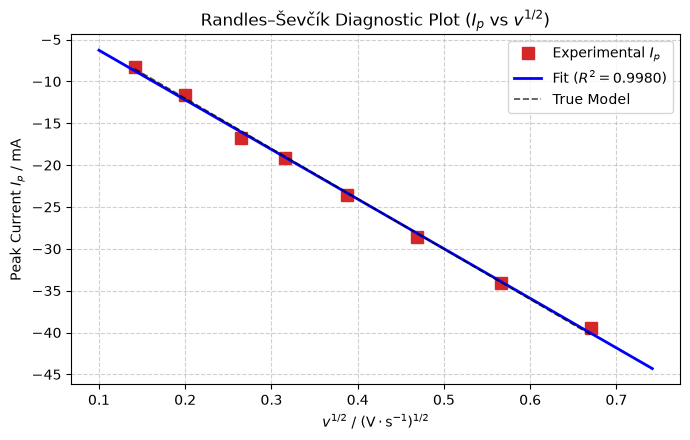

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from softpotato.analytical.voltammetry import randles_sevcik
from softpotato.analytical.fitting import fit_randles_sevcik

# Experimental parameters
n = 1
area = 0.0707                         # 3 mm diameter disc electrode (cm^2)
c_bulk = 1.0e-3                       # 1 mM concentration (mol/cm^3)
true_D = 1.0e-5                       # True diffusion coefficient (cm^2/s)

# Measured scan rates from 0.02 V/s (20 mV/s) to 0.50 V/s (500 mV/s)
scan_rates = np.array([0.02, 0.04, 0.07, 0.10, 0.15, 0.22, 0.32, 0.45])

# 1. Generate exact peak currents using randles_sevcik()
# Note: Following electrochemical conventions, cathodic peak current is negative
ip_exact = randles_sevcik(scan_rates, n=n, D=true_D, c_bulk=c_bulk, area=area)

# 2. Add synthetic experimental noise (2.5% of mean magnitude)
noise = rng.normal(loc=0.0, scale=0.025 * np.abs(np.mean(ip_exact)), size=scan_rates.shape)
ip_experimental = ip_exact + noise

# 3. Fit peak currents vs scan rate with fit_randles_sevcik
res_rs = fit_randles_sevcik(
    scan_rate=scan_rates,
    peak_current=ip_experimental,
    method="linear",
    model="reversible",
    n=n,
    area=area,
    c_bulk=c_bulk,
    fit_intercept=True,
    confidence_level=0.95,
)

# 4. Display results and confidence bounds
ci_d = res_rs.confidence_intervals["D"]
print("=== Randles–Ševčík Voltammetric Fitting Results ===")
print(f"True D:              {true_D:.4e} cm²/s")
print(f"Extracted D:         {res_rs.d:.4e} ± {res_rs.d_stderr:.4e} cm²/s")
print(f"95% Confidence Int:  [{ci_d[0]:.4e}, {ci_d[1]:.4e}] cm²/s")
print(f"Fitted slope:        {res_rs.slope:.4e} A/(V/s)^(1/2)")
print(f"Fitted intercept:    {res_rs.intercept:.4e} A")
print(f"Coefficient R²:      {res_rs.r_squared:.6f}")
print(f"RMSE:                {res_rs.rmse:.4e} A")

# 5. Diagnostic Plot: Ip vs sqrt(v)
v_sqrt = np.sqrt(scan_rates)
v_dense = np.linspace(0.01, 0.55, 100)
ip_dense_fit = (res_rs.slope * np.sqrt(v_dense) + res_rs.intercept) * 1e3

plt.figure(figsize=(7, 4.5))
plt.plot(v_sqrt, ip_experimental * 1e3, "s", color="#d62728", markersize=8, label="Experimental $I_p$")
plt.plot(np.sqrt(v_dense), ip_dense_fit, "b-", lw=2, label=f"Fit ($R^2 = {res_rs.r_squared:.4f}$)")
plt.plot(v_sqrt, ip_exact * 1e3, "k--", lw=1.2, alpha=0.7, label="True Model")
plt.xlabel(r"$v^{1/2}$ / $(\mathrm{V}\cdot\mathrm{s}^{-1})^{1/2}$")
plt.ylabel(r"Peak Current $I_p$ / mA")
plt.title(r"Randles–Ševčík Diagnostic Plot ($I_p$ vs $v^{1/2}$)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

---

## 4. SECM Approach Curves: `fit_secm_approach()`

In Scanning Electrochemical Microscopy (SECM), steady-state approach curves record the normalized tip current $I_T = i_T / i_{T,\infty}$ as a microelectrode probe approaches a substrate:

$$I_T(d) = I_T^{\text{model}}\left(\frac{d - d_{\text{offset}}}{a}, \, RG, \, \kappa\right)$$

where:
- $a$ is the active microdisc radius in meters,
- $RG = r_g / a$ is the insulator glass sheath to core radius ratio ($RG \ge 1.0$),
- $d$ is the experimental stage z-axis position in meters,
- $d_{\text{offset}}$ is the zero-distance vertical positioning offset,
- $\kappa$ is the dimensionless substrate reaction rate constant (conductive substrate: $\kappa \to \infty$; insulating substrate: $\kappa = 0$).

In real experiments, the exact substrate contact coordinate $d_{\text{offset}}$ cannot be known a priori without fitting or touching down, and fabricated tip geometries $RG$ often differ slightly from nominal values. `fit_secm_approach()` non-linearly fits $RG$ and $d_{\text{offset}}$ simultaneously against the analytical Lefrou & Cornut equations.

Below, we generate synthetic approach curve data with `softpotato.analytical.secm.secm_approach_curve`, add noise, and fit for $RG$ and $d_{\text{offset}}$.


=== SECM Approach Curve Fitting Results ===
True RG:             7.50
Extracted RG:        7.436 ± 0.405
True offset:         2.000 µm
Extracted offset:    1.998 ± 0.004 µm
Coefficient R²:      0.999878
RMSE:                1.0069e-02


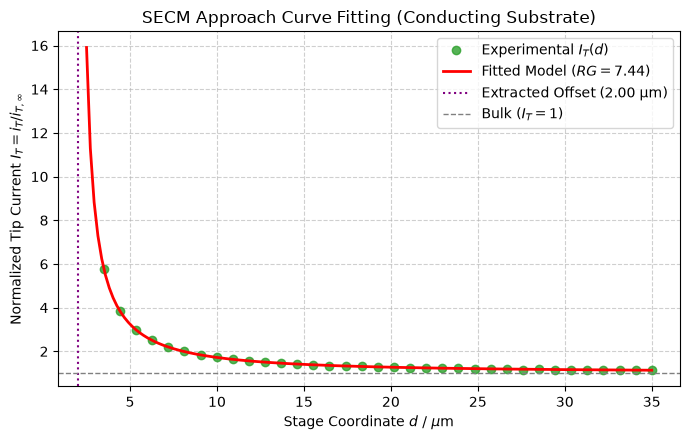

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from softpotato.analytical.secm import secm_approach_curve
from softpotato.analytical.fitting import fit_secm_approach

# Microelectrode probe geometry
tip_radius = 10e-6                    # Active disc radius a = 10 µm (1e-5 m)
true_rg = 7.5                         # True sheath ratio RG = rg / a
true_offset = 2.0e-6                  # True stage offset: d_offset = 2.0 µm (2e-6 m)

# Experimental stage z-positions from 3.5 µm to 35 µm
d_stage = np.linspace(3.5e-6, 35e-6, 35)

# Calculate true normalized distance L = (d - d_offset) / a
L_true = (d_stage - true_offset) / tip_radius

# 1. Generate exact positive-feedback approach curve (conducting substrate, kappa = inf)
it_exact = secm_approach_curve(L=L_true, RG=true_rg, kappa=np.inf)

# 2. Add realistic measurement noise (standard error ~ 0.015 in normalized current)
noise = rng.normal(loc=0.0, scale=0.015, size=d_stage.shape)
it_experimental = it_exact + noise

# 3. Fit approach curve to extract RG and d_offset simultaneously
res_secm = fit_secm_approach(
    distance=d_stage,
    normalized_current=it_experimental,
    substrate="conducting",
    a=tip_radius,
    fit_rg=True,
    fit_d_offset=True,
    p0=[5.0, 0.0],                    # Initial parameter guesses: RG = 5, offset = 0 µm
    confidence_level=0.95,
)

# 4. Display extracted parameters and confidence intervals
print("=== SECM Approach Curve Fitting Results ===")
print(f"True RG:             {true_rg:.2f}")
print(f"Extracted RG:        {res_secm.rg:.3f} ± {res_secm.stderr.get('rg', 0.0):.3f}")
print(f"True offset:         {true_offset * 1e6:.3f} µm")
print(f"Extracted offset:    {res_secm.d_offset * 1e6:.3f} ± {res_secm.stderr.get('d_offset', 0.0) * 1e6:.3f} µm")
print(f"Coefficient R²:      {res_secm.r_squared:.6f}")
print(f"RMSE:                {res_secm.rmse:.4e}")

# 5. Diagnostic Plot: IT vs stage position d
d_dense = np.linspace(2.5e-6, 35e-6, 150)
L_dense = (d_dense - res_secm.d_offset) / tip_radius
it_dense_fit = secm_approach_curve(L=L_dense, RG=res_secm.rg, kappa=np.inf)

plt.figure(figsize=(7, 4.5))
plt.plot(d_stage * 1e6, it_experimental, "o", color="#2ca02c", alpha=0.8, label="Experimental $I_T(d)$")
plt.plot(d_dense * 1e6, it_dense_fit, "r-", lw=2, label=f"Fitted Model ($RG = {res_secm.rg:.2f}$)")
plt.axvline(res_secm.d_offset * 1e6, color="purple", ls=":", lw=1.5, label=f"Extracted Offset ({res_secm.d_offset*1e6:.2f} µm)")
plt.axhline(1.0, color="gray", ls="--", lw=1.0, label="Bulk ($I_T = 1$)")
plt.xlabel(r"Stage Coordinate $d$ / $\mu\mathrm{m}$")
plt.ylabel(r"Normalized Tip Current $I_T = i_T / i_{T,\infty}$")
plt.title("SECM Approach Curve Fitting (Conducting Substrate)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

---

## 5. Arbitrary User-Defined Equation: `fit_curve()`

When working with non-standard experimental models—such as custom kinetic mechanisms, adsorption isotherms, double-layer capacitance relaxations, or empirical calibration equations—Soft Potato provides `fit_curve()`.

`fit_curve()` wraps `scipy.optimize.curve_fit` to provide a complete, production-grade statistical diagnosis:
- Named parameter tracking (`param_names`)
- Physical bounding constraints (`bounds=([lowers], [uppers])`)
- Asymptotic standard errors (`res.stderr`)
- Parameter covariance matrix (`res.covariance`) and correlation matrix (`res.correlation`)
- Two-tailed Student's $t$ confidence intervals (`res.confidence_intervals`)
- Goodness-of-fit metrics: $R^2$ (`res.r_squared`), adjusted $R^2$ (`res.r_squared_adj`), RMSE (`res.rmse`), and reduced chi-squared $\chi_\nu^2$ (`res.chi2_reduced`)
- Full residual diagnostics (`res.residuals`)

Below, we define a classic **Langmuir Adsorption Isotherm** model:

$$\theta(c) = \frac{\theta_{\max} K_{\text{ads}} c}{1 + K_{\text{ads}} c}$$

where:
- $\theta_{\max}$ is the saturation surface coverage ($\text{pmol/cm}^2$),
- $K_{\text{ads}}$ is the equilibrium adsorption affinity constant ($\text{mM}^{-1}$),
- $c$ is the solution bulk concentration ($\text{mM}$).


=== fit_curve Statistical Diagnostics ===
Convergence:           True (Optimal parameters found.)
R²:                    0.996301
Adjusted R²:           0.996096
RMSE:                  4.6226e+00 pmol/cm²
Reduced Chi-squared:   2.3743e+01

--- Extracted Parameters & 95% Confidence Intervals ---
theta_max  = 2.4801e+02 ± 3.6911e+00  (95% CI: [2.4026e+02, 2.5576e+02])
K_ads      = 3.9607e+00 ± 1.8467e-01  (95% CI: [3.5727e+00, 4.3486e+00])

--- Parameter Correlation Matrix ---
[[ 1.     -0.8268]
 [-0.8268  1.    ]]


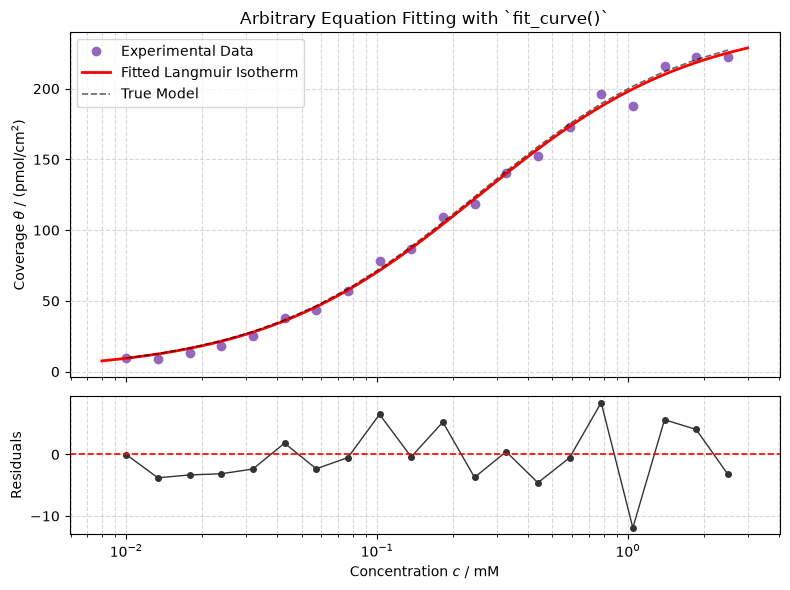

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from softpotato.analytical.fitting import fit_curve

# Define arbitrary equation manually as a standard Python function
def langmuir_isotherm(c, theta_max, k_ads):
    # Langmuir adsorption isotherm model
    return (theta_max * k_ads * c) / (1.0 + k_ads * c)

# True physical parameters in practical scientific units
true_theta_max = 250.0                # Saturation surface coverage (pmol/cm^2)
true_k_ads = 4.0                      # Adsorption affinity constant (1/mM)

# Experimental concentrations: 0.01 mM to 2.5 mM (20 points spaced geometrically)
concentrations = np.geomspace(0.01, 2.5, 20)

# 1. Generate exact model data
theta_exact = langmuir_isotherm(concentrations, true_theta_max, true_k_ads)

# 2. Add realistic measurement noise (3% proportional error + baseline jitter)
noise = rng.normal(loc=0.0, scale=0.03 * theta_exact + 2.0, size=concentrations.shape)
theta_experimental = theta_exact + noise

# 3. Fit using fit_curve with parameter names and physical bounds
res_custom = fit_curve(
    model=langmuir_isotherm,
    xdata=concentrations,
    ydata=theta_experimental,
    p0=[100.0, 2.0],                  # Initial parameter guesses
    bounds=([0.0, 0.0], [1000.0, 100.0]), # Physical constraints: theta_max > 0, K_ads > 0
    param_names=["theta_max", "K_ads"],
    confidence_level=0.95,
)

# 4. Inspect detailed statistical output
print("=== fit_curve Statistical Diagnostics ===")
print(f"Convergence:           {res_custom.success} ({res_custom.message})")
print(f"R²:                    {res_custom.r_squared:.6f}")
print(f"Adjusted R²:           {res_custom.r_squared_adj:.6f}")
print(f"RMSE:                  {res_custom.rmse:.4e} pmol/cm²")
print(f"Reduced Chi-squared:   {res_custom.chi2_reduced:.4e}")

print("\n--- Extracted Parameters & 95% Confidence Intervals ---")
for name in ["theta_max", "K_ads"]:
    val = res_custom.params[name]
    err = res_custom.stderr[name]
    ci = res_custom.confidence_intervals[name]
    print(f"{name:10s} = {val:.4e} ± {err:.4e}  (95% CI: [{ci[0]:.4e}, {ci[1]:.4e}])")

print("\n--- Parameter Correlation Matrix ---")
print(np.array2string(res_custom.correlation, precision=4, suppress_small=True))

# 5. Diagnostic Plot: Model Fit & Residuals
fig, (ax_fit, ax_res) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True, gridspec_kw={"height_ratios": [2.5, 1]}
)

c_dense = np.geomspace(0.008, 3.0, 200)
theta_dense_fit = langmuir_isotherm(c_dense, res_custom.params["theta_max"], res_custom.params["K_ads"])

# Subplot 1: Data and Fit
ax_fit.plot(concentrations, theta_experimental, "o", color="#9467bd", label="Experimental Data")
ax_fit.plot(c_dense, theta_dense_fit, "r-", lw=2, label="Fitted Langmuir Isotherm")
ax_fit.plot(concentrations, theta_exact, "k--", lw=1.2, alpha=0.6, label="True Model")
ax_fit.set_ylabel(r"Coverage $\theta$ / ($\mathrm{pmol/cm}^2$)")
ax_fit.set_title("Arbitrary Equation Fitting with `fit_curve()`")
ax_fit.set_xscale("log")
ax_fit.grid(True, which="both", linestyle="--", alpha=0.5)
ax_fit.legend()

# Subplot 2: Residuals
ax_res.plot(concentrations, res_custom.residuals, "o-", color="#333333", ms=4, lw=1)
ax_res.axhline(0.0, color="red", linestyle="--", lw=1.2)
ax_res.set_xlabel("Concentration $c$ / mM")
ax_res.set_ylabel(r"Residuals")
ax_res.set_xscale("log")
ax_res.grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---

## 6. Summary: Best Practices for Data Fitting

When analyzing experimental electrochemical data in Soft Potato:

1. **Leverage Pre-built Routines**: Use specialized functions (`fit_cottrell`, `fit_randles_sevcik`, `fit_secm_approach`, `fit_levich`, `fit_tafel`, etc.) for standard techniques. They automatically handle equation setups, method selection (`linear` vs `nonlinear`), and map slopes/intercepts directly into physical constants ($D$, $k^0$, $\alpha$, $RG$).
2. **Use `fit_curve()` for Custom Models**: For non-standard reactions or arbitrary calibration curves, pass your custom Python function directly to `fit_curve()`. Supply descriptive `param_names` and physically realistic `bounds`.
3. **Verify the Statistical Diagnostics**:
   - Inspect `res.r_squared` and `res.rmse` for overall goodness-of-fit.
   - Check `res.stderr` and `res.confidence_intervals` to assess the certainty of extracted parameters.
   - Review `res.correlation` to ensure parameters are not heavily co-dependent or overparameterized.
   - Inspect `res.residuals` to verify that experimental residuals are randomly scattered without systematic trends.
4. **Maintain Unit Consistency**: Always ensure independent variables and known parameters use a consistent unit system (SI or CGS) matching the equation's documentation.

To explore all available fitting routines and result classes, visit the [Parameter Fitting API Reference](/api/analytical/fitting).
